# AA 279B Homework 1


## Problem 1

In [186]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [187]:
import numpy as np
from numpy.linalg import norm
from scipy.integrate import solve_ivp
from scipy.optimize import root_scalar
import matplotlib.pyplot as plt
from IPython.display import display, Latex
import plotly.graph_objects as go
from tqdm import tqdm
from dataclasses import dataclass

In [188]:
DAY_TO_SEC = 24 * 60 * 60
MIN_TO_SEC = 60

# km3/m2
MU_EARTH = 398600
MU_MOON = 4903

# km
r_EARTH_MOON = 384400
R_EARTH = 6378.0
R_MOON = 1738.0 

# Barycenter
r_bc_earth = MU_MOON / (MU_MOON + MU_EARTH) * r_EARTH_MOON
r_bc_moon = MU_EARTH / (MU_MOON + MU_EARTH) * r_EARTH_MOON

# w_s
w_earth_moon = np.sqrt( (MU_EARTH + MU_MOON) / r_EARTH_MOON**3)

### L2 (part a)

In [189]:
def earth_moon_two_body(x):
    return (MU_EARTH / (x + r_bc_earth)**2 +
            MU_MOON / (x - r_bc_moon)**2 -
            w_earth_moon**2 * x
            )

r_L2_x = root_scalar(
    earth_moon_two_body,
    bracket=[r_bc_moon + 0.001, r_bc_moon*2]).root

r_L2 = np.array([r_L2_x, 0, 0])
print(f"L2: {r_L2_x}km -> {r_L2}")

L2: 444244.96544722747km -> [444244.96544723      0.              0.        ]


### Sim (part b)

In [190]:
def synodic_dynamics(state, mu1, mu2, R1, R2, w_s):
    """mu1/R1 for larger body"""    
    assert mu1 > mu2
    assert R1 < R2
    
    x, y, z, x_dot, y_dot, z_dot = state
    
    r_1_sat = np.sqrt((x + R1)**2 + y**2 + z**2)
    r_2_sat = np.sqrt((x - R2)**2 + y**2 + z**2)
    
    x_ddot = (
        -mu1 * (x + R1) / (r_1_sat**3)
        -mu2 * (x - R2) / (r_2_sat**3)
        + 2 * w_s * y_dot
        + w_s**2 * x)
    
    y_ddot = (
        -mu1 * y / (r_1_sat**3)
        -mu2 * y / (r_2_sat**3)
        - 2 * w_s * x_dot
        + w_s**2 * y)
    
    z_ddot = (
        -mu1 * z / (r_1_sat**3)
        -mu2 * z / (r_2_sat**3))
    
    return np.array([x_dot, y_dot, z_dot, x_ddot, y_ddot, z_ddot])

In [191]:
# Wrapper
def earth_moon_synodic_dynamics(t, state):
    del t
    return synodic_dynamics(state, MU_EARTH, MU_MOON, r_bc_earth, r_bc_moon, w_earth_moon)

In [192]:
# Initial conditions

sim_length = 4.0 * DAY_TO_SEC
t_arr_4_day = np.linspace(0, sim_length, 100000)

convergence_bound = 1 # km

In [193]:
# VERY SPECIFIC to Earth
def earth_inputs_to_state(phi_inj, v_inj, altitude = 200):
    state0 = np.zeros(6)

    rho_earth_sat = altitude + R_EARTH
    # x,y
    state0[0] = -rho_earth_sat*np.cos(phi_inj) - r_bc_earth
    state0[1] = -rho_earth_sat*np.sin(phi_inj)

    # vx,vy
    state0[3] =  v_inj * np.sin(phi_inj)
    state0[4] = -v_inj * np.cos(phi_inj)
    
    return state0

In [194]:
# Shoot.
def simulate_earth_moon(t_arr, state0):
    t_span = (t_arr[0], t_arr[-1])
    return solve_ivp(earth_moon_synodic_dynamics, t_span, state0, method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9)

def jacobian(phi_inj, v_inj, t_arr, delta = 0.001):
    """2 inputs to 3 outputs (r) -> (1,2) matrix"""
    
    # phi variation
    phi_sim_upper = simulate_earth_moon(t_arr, earth_inputs_to_state(phi_inj + delta, v_inj)).y
    phi_sim_lower = simulate_earth_moon(t_arr, earth_inputs_to_state(phi_inj - delta, v_inj)).y
    
    dr_dphi = (phi_sim_upper[0:3,-1]  - phi_sim_lower[0:3,-1] ) / (2*delta)
    
    # vel variation
    vel_sim_upper = simulate_earth_moon(t_arr, earth_inputs_to_state(phi_inj, v_inj + delta)).y
    vel_sim_lower = simulate_earth_moon(t_arr, earth_inputs_to_state(phi_inj, v_inj - delta)).y
    
    dr_dv = (vel_sim_upper[0:3,-1] - vel_sim_lower[0:3,-1]) / (2*delta)
    
    return np.hstack((dr_dphi.reshape((3,-1)), dr_dv.reshape((3,-1))))
    # return np.concat((dr_dphi, dr_dv)).reshape(6,-1)

In [195]:
"""
Pseudocode:
- Seed loosely around previous trajectory
- Keep N trajectories 
"""

def find_initial_conditions(t_arr, phi0_deg = 45, v_inj_km_s = 11, verbose = False):

    phi_arr = [np.deg2rad(phi0_deg)]
    v_inj_arr = [v_inj_km_s]
    sim_arr = []

    iter = 10
    for i in range(iter):
        sim = simulate_earth_moon(t_arr, earth_inputs_to_state(phi_arr[-1], v_inj_arr[-1])).y
        sim_arr.append(sim)
        
        dr = sim[0:3,-1] - r_L2
        dr_norm = norm(dr)
        
        if verbose:
            print(f"dr: {dr_norm:.5f}km")
        
        if norm(dr) < convergence_bound:
            print(f"\nConverged with:\n\tdr = {dr_norm:.5f} km")
            break
        
        J = jacobian(phi_arr[-1], v_inj_arr[-1], t_arr)
        
        new = [phi_arr[-1], v_inj_arr[-1]] - np.linalg.pinv(J) @ dr
        
        phi_arr.append(new[0])
        v_inj_arr.append(new[1])
    
    return sim_arr, phi_arr, v_inj_arr

In [196]:
sims, phis, v_injs = find_initial_conditions(t_arr_4_day, phi0_deg = 45, v_inj_km_s = 11, verbose = True)
first_sim = sims[0]
sim = sims[-1]
phi = np.rad2deg(phis[-1])
v_inj = v_injs[-1]

dr: 262888.69755km
dr: 111685.42353km
dr: 39045.19353km
dr: 1936.39399km
dr: 5.75182km
dr: 0.00001km

Converged with:
	dr = 0.00001 km


### Plotting (part c)

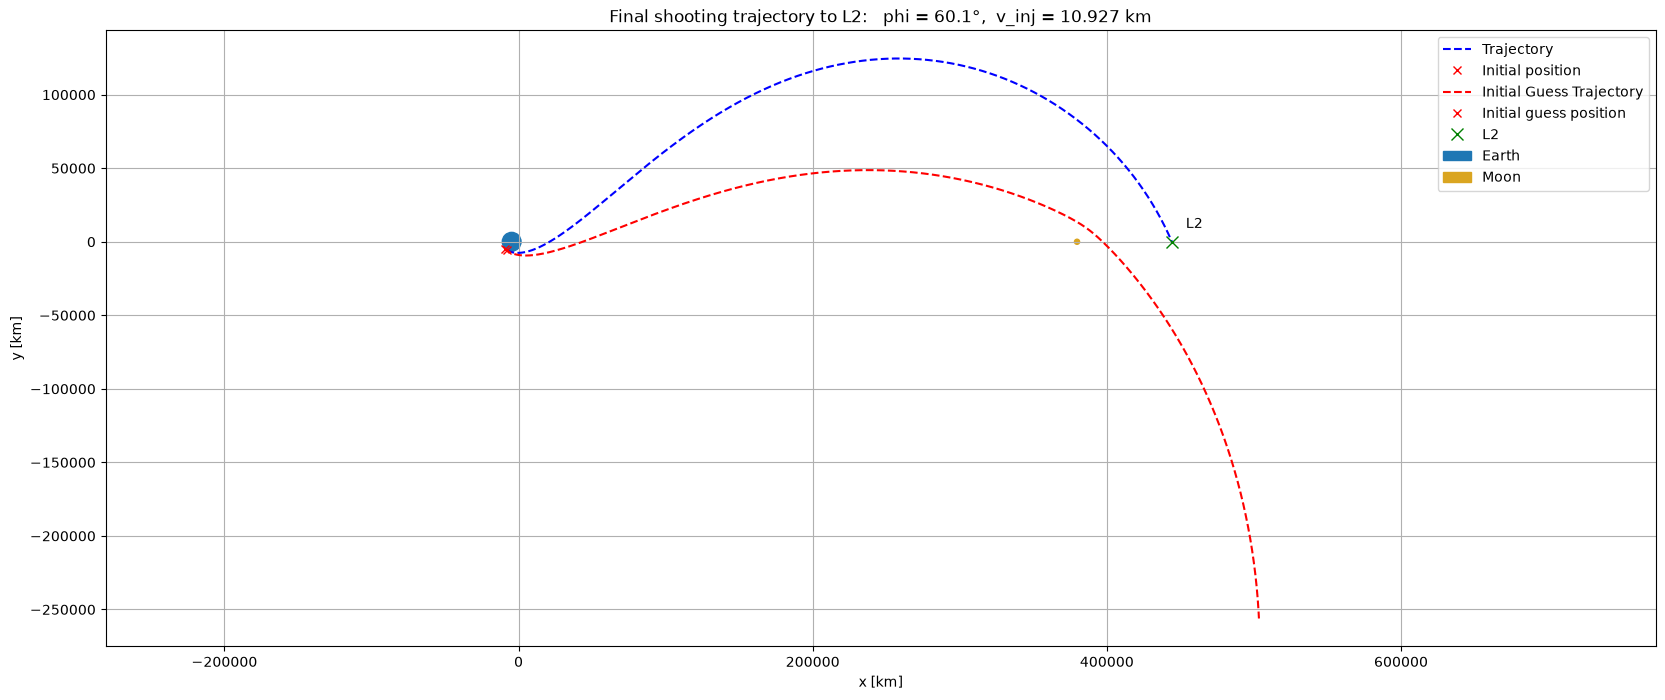

In [197]:
fig, ax = plt.subplots(figsize=(20, 8))
ax.set_title(f'Final shooting trajectory to L2:   phi = {phi:.1f}\u00b0,  v_inj = {v_inj:.3f} km')

# Trajectory
ax.plot(sim[0], sim[1], 'b--', label='Trajectory')
ax.plot(sim[0,0], sim[1,1], 'rx', label='Initial position')
ax.plot(first_sim[0], first_sim[1], 'r--', label='Initial Guess Trajectory')
ax.plot(first_sim[0,0], first_sim[1,1], 'rx', label='Initial guess position')

# Bodies
# ax.plot(-r_bc_earth, 0, "bo", markersize=5, label="Earth")
ax.plot(r_L2_x, 0, "x", color="green", markersize=8, label="L2")
plt.annotate("L2", xy=(r_L2_x,0),textcoords="offset points", xytext=(10,10))

ax.add_patch(plt.Circle((-r_bc_earth,0), R_EARTH, color='tab:blue', fill=True, label="Earth"))
ax.add_patch(plt.Circle((r_bc_moon,0), R_MOON, color='goldenrod', fill=True, label="Moon"))

ax.set_xlabel('x [km]')
ax.set_ylabel('y [km]')
ax.set_aspect('equal', adjustable='datalim')

ax.grid(True)
ax.legend()
plt.show()

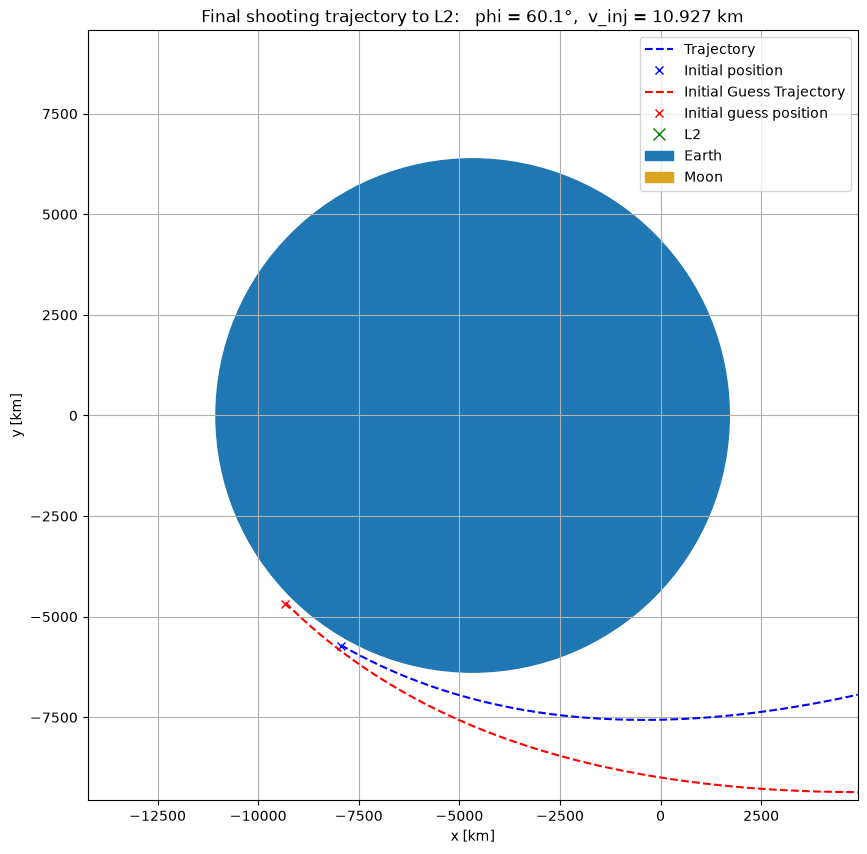

In [198]:
# Around Earth

fig, ax = plt.subplots(figsize=(20, 10))
ax.set_title(f'Final shooting trajectory to L2:   phi = {phi:.1f}\u00b0,  v_inj = {v_inj:.3f} km')

# Trajectory
ax.plot(sim[0], sim[1], 'b--', label='Trajectory')
ax.plot(sim[0,0], sim[1,1], 'bx', label='Initial position')
ax.plot(first_sim[0], first_sim[1], 'r--', label='Initial Guess Trajectory')
ax.plot(first_sim[0,0], first_sim[1,1], 'rx', label='Initial guess position')

# Bodies
# ax.plot(-r_bc_earth, 0, "bo", markersize=5, label="Earth")
ax.plot(r_L2_x, 0, "x", color="green", markersize=8, label="L2")
plt.annotate("L2", xy=(r_L2_x,0),textcoords="offset points", xytext=(10,10))

ax.add_patch(plt.Circle((-r_bc_earth,0), R_EARTH, color='tab:blue', fill=True, label="Earth"))
ax.add_patch(plt.Circle((r_bc_moon,0), R_MOON, color='goldenrod', fill=True, label="Moon"))

ax.set_xlabel('x [km]')
ax.set_ylabel('y [km]')
ax.set_aspect('equal')

ax.grid(True)
ax.legend()
ax.set_xlim(-r_bc_earth - R_EARTH*1.5, -r_bc_earth + R_EARTH*1.5)
ax.set_ylim(-R_EARTH*1.5, R_EARTH*1.5)
plt.show()

### v_retro (part d)

In [199]:
dv_retro_L2 = norm(sim[3:6,-1])
print(f"dV_L2: {dv_retro_L2}")

dV_L2: 1.2306210650865435


### Prop estimate (part e)

In [200]:
def calc_dv_tot(sim):
    dv_retro_L2 = norm(sim[3:6,-1])
    rho = R_EARTH + 200
    v_orbital = np.sqrt(MU_EARTH / rho - w_earth_moon * rho)
    dv_tot = v_inj - v_orbital + dv_retro_L2
    print(f"dv_tot: {dv_tot} km/s")
    
dv_tot = calc_dv_tot(sim)

dv_tot: 4.374548381075959 km/s


### Optimizing fuel

In [201]:
# N = 100
N = 0
day_arr = np.linspace(6,7,N)
t_arr_days = [np.linspace(0, day * DAY_TO_SEC, 100000) for day in day_arr]
dv_tot_arr = np.zeros_like(t_arr_days)

for i in tqdm(range(N)):
    sims, phis, v_injs = find_initial_conditions(t_arr_days[i], phi0_deg = 45, v_inj_km_s = 11)
    sim = sims[-1]
    phi = np.rad2deg(phis[-1])
    v_inj = v_injs[-1]
    
    dv_tot_arr[i] = calc_dv_tot(sim)

0it [00:00, ?it/s]


## Problem 2

### part a

In [202]:
r_I = np.array([343777.2401, 0.0, -27449.52657])
v_I = np.array([0.0, -0.2769119497, 0.0])

In [203]:
t_arr_30 = np.linspace(0, 30 * DAY_TO_SEC, 100000)
sim_30 = simulate_earth_moon(t_arr_30, np.concatenate((r_I, v_I))).y

In [204]:
def plot_3d_(r, markers = None):

    fig = go.Figure()

    # Satellite orbit
    fig.add_trace(go.Scatter3d(
        x=r[0],
        y=r[1],
        z=r[2],
        mode="lines",
        name="Satellite orbit",
        line=dict(color="royalblue", width=5)
    ))

    # Satellite's final/current position
    fig.add_trace(go.Scatter3d(
        x=[r[0, -1]],
        y=[r[1, -1]],
        z=[r[2, -1]],
        mode="markers",
        name="Satellite",
        marker=dict(size=6, color="blue")
    ))

    # L2 point
    
    markers = markers if markers else []
    for marker in markers:
        fig.add_trace(go.Scatter3d(
            x=[marker[0]],
            y=[marker[1]],
            z=[marker[2]],
            mode="markers+text",
            name="L2 point",
            text=["L2"],
            textposition="top center",
            marker=dict(size=8, color="red", symbol="diamond")
        ))

    fig.update_layout(
        title="3D Satellite Orbit and L2 Point",
        scene=dict(
            xaxis_title="x",
            yaxis_title="y",
            zaxis_title="z",
            aspectmode="data"
        ),
        template="plotly_white",
        legend=dict(x=0.02, y=0.98)
    )
    fig.update_layout(height=900)

    fig.show()

In [205]:
plot_3d_(sim_30[:3, :], [r_L2])

In [206]:
def estimate_periods(sim):
    y_halo = sim[2, :]
    y_crossings_ascending = np.where((y_halo[:-1] <= 0) & (y_halo[1:] > 0))[0] + 1
    t_crossings = t_arr_30[y_crossings_ascending]
    periods = np.array([t_crossings[i+1] - t_crossings[i] for i in range(len(t_crossings) - 1)])
    
    return periods


periods = estimate_periods(sim_30)
print(f"Periods: {periods}s ({periods / DAY_TO_SEC} day)")

Periods: [1044975.2497525  1086914.22914229]s ([12.09462095 12.5800258 ] day)


### part 2

In [207]:
r_I_2 = np.array([343117.419, 0.0, 76029.48372])

v_I_2 = np.array([0.0, 0.2045850249, 0.0])

t_arr_30_2 = np.linspace(0, 30 * DAY_TO_SEC, 100000)
sim_30_2 = simulate_earth_moon(t_arr_30_2, np.concatenate((r_I_2, v_I_2))).y

plot_3d_(sim_30_2[:3, :])

In [208]:
periods = estimate_periods(sim_30_2)
print(f"Periods: {periods}s ({periods / DAY_TO_SEC} day)")

Periods: [745829.53829538 745803.61803618]s ([8.63228632 8.63198632] day)


## Problem 3

In [209]:
target_alt = 760  # km
chaser_r0 = np.array([25, -75])  # 2D [x,y,vx,vy]
chaser_v0 = np.array([0, 0])  # 2D [x,y,vx,vy]
intercept_time = 10 * MIN_TO_SEC

r_goal = np.array([0,0])
v_goal = np.array([0,0])

In [210]:
mean_motion = np.sqrt(MU_EARTH / (R_EARTH + target_alt)**3)

### part a

In [211]:
@dataclass 
class Phi:
    rr: np.ndarray
    rv: np.ndarray
    vv: np.ndarray
    vr: np.ndarray


def calc_Phi(t, n):
    nt = n * t
    Phi_rr = np.array([[4 - 3*np.cos(nt), 0], [6 * (np.sin(nt) - nt), 1]])
    Phi_rv = np.array([
        [1/mean_motion * np.sin(nt), 2/mean_motion * (1 - np.cos(nt))],
        [2/mean_motion * (np.cos(nt) - 1), 4/mean_motion * np.sin(nt) - 3/mean_motion * nt]
        ])
    Phi_vr = np.array([[3*mean_motion*np.sin(nt), 0], [6*mean_motion*(np.cos(nt) - 1), 0]])
    Phi_vv = np.array([
        [np.cos(nt), 2*np.sin(nt)],
        [-2*np.sin(nt), 4*np.cos(nt) - 3]
        ])
    
    return Phi(rr=Phi_rr, rv=Phi_rv, vv=Phi_vv, vr=Phi_vr)

phi = calc_Phi(intercept_time, mean_motion)

dv_start = np.linalg.pinv(phi.rv) @ (r_goal - phi.rr @ chaser_r0) - chaser_v0
print(f"dv_start: {norm(dv_start):.3f} km/s   ({dv_start})")

dv_start: 0.147 km/s   ([-0.12292895  0.08140932])


### part b

In [212]:
dv_end = v_goal - (phi.vr @ chaser_r0 + phi.vv @ (chaser_v0 + dv_start))
print(f"dv_end: {norm(dv_end):.3f} km/s   ({dv_end})")

dv_tot = norm(dv_end) + norm(dv_start)

print(f"\ndv_tot: {dv_tot:.3f} km/s")


dv_end: 0.140 km/s   ([-0.04235379 -0.13375416])

dv_tot: 0.288 km/s


In [213]:

t_hcw = np.arange(0, intercept_time + 1)

def calc_r_hcw(t, n, r0, v0):
    nt = n * t
    Phi_rr = np.array([[4 - 3*np.cos(nt), 0], [6 * (np.sin(nt) - nt), 1]])
    Phi_rv = np.array([
        [1/n * np.sin(nt), 2/n * (1 - np.cos(nt))],
        [2/n * (np.cos(nt) - 1), 4/n * np.sin(nt) - 3/n * nt]
        ])
    return Phi_rr @ r0 + Phi_rv @ v0

r_hcw = np.array([calc_r_hcw(t_i, mean_motion, chaser_r0, dv_start) for t_i in t_hcw])
x_hcw = r_hcw[:,0]
y_hcw = r_hcw[:,1]

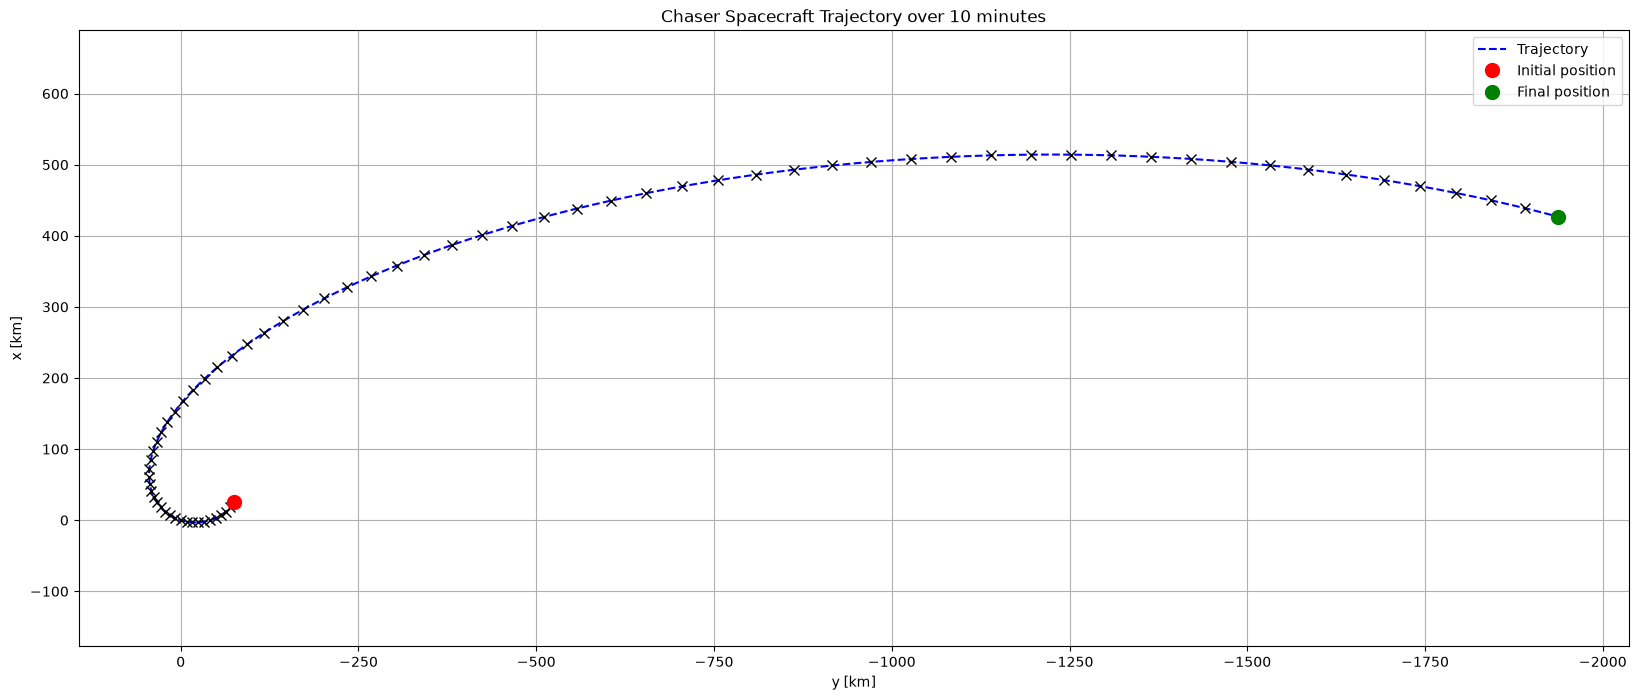

In [227]:
fig, ax = plt.subplots(figsize=(20, 8))
ax.set_title('Chaser Spacecraft Trajectory over 10 minutes')

# Trajectory
ax.plot(y_hcw, x_hcw, 'b--', label='Trajectory')


for i in range(0, len(x_hcw), MIN_TO_SEC):
    ax.plot(y_hcw[i], x_hcw[i], 'kx', markersize=7)

ax.plot(y_hcw[0], x_hcw[0], 'ro', markersize=10, label='Initial position')
ax.plot(y_hcw[-1], x_hcw[-1], 'go', markersize=10, label='Final position')

ax.set_xlabel('y [km]')
ax.set_ylabel('x [km]')
ax.set_aspect('equal', adjustable='datalim')
ax.set_xinverted(True)

ax.grid(True)
ax.legend()
plt.show()

### part c

In [215]:
tf_arr = np.arange(1, 121)

def calc_v_tot(intercept_time_s,n,r0,v0,r_goal=np.zeros(2),v_goal=np.zeros(2)):
    phi = calc_Phi(intercept_time_s, n)

    dv_start = np.linalg.pinv(phi.rv) @ (r_goal - phi.rr @ r0) - v0
    dv_end = v_goal - (phi.vr @ r0 + phi.vv @ (v0 + dv_start))

    return norm(dv_start) + norm(dv_end)

dv_arr = np.array([calc_v_tot(tf * MIN_TO_SEC, mean_motion, chaser_r0, chaser_v0) for tf in tf_arr])

dv_arr[dv_arr > 5] = np.nan

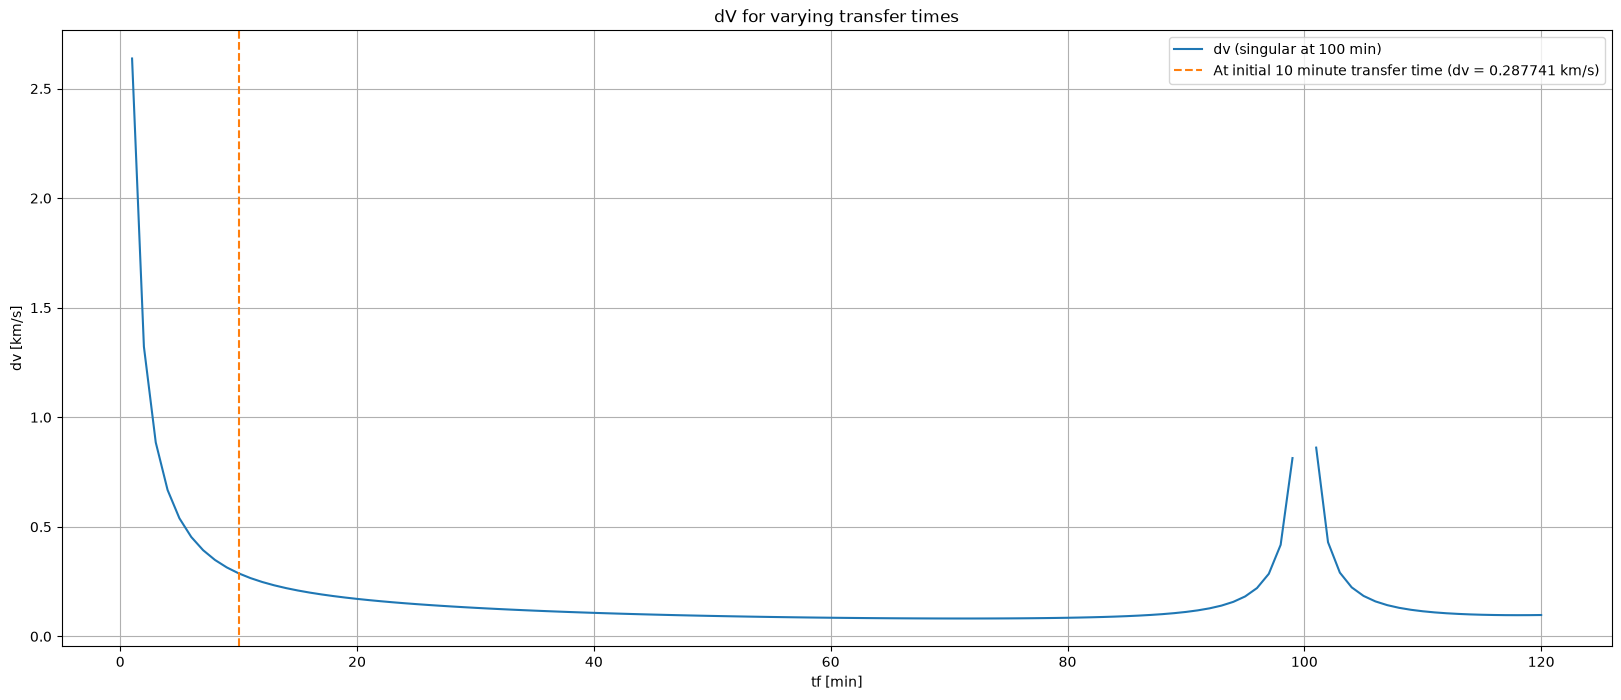

In [216]:
fig, ax = plt.subplots(figsize=(20, 8))
ax.set_title('dV for varying transfer times')

# Trajectory
ax.plot(tf_arr, dv_arr, label="dv (singular at 100 min)")
ax.axvline(10, linestyle="--", color="tab:orange", label=f'At initial 10 minute transfer time (dv = {dv_tot:2f} km/s)')

ax.set_ylabel('dv [km/s]')
ax.set_xlabel('tf [min]')

ax.grid(True)
ax.legend()

plt.show()

### part d

In [217]:
dv_min = np.nanmin(dv_arr)
t_dv_min = tf_arr[np.nanargmin(dv_arr)]

print(f"Minimum:\n\tdv = {dv_min:.4f} km/s\nat\n\tt = {t_dv_min} min")

Minimum:
	dv = 0.0816 km/s
at
	t = 71 min


In [218]:
def calc_r_hcw(t, n, r0, v0):
    nt = n * t
    Phi_rr = np.array([[4 - 3*np.cos(nt), 0], [6 * (np.sin(nt) - nt), 1]])
    Phi_rv = np.array([
        [1/n * np.sin(nt), 2/n * (1 - np.cos(nt))],
        [2/n * (np.cos(nt) - 1), 4/n * np.sin(nt) - 3/n * nt]
        ])
    return Phi_rr @ r0 + Phi_rv @ v0

t_hcw = np.arange(0, t_dv_min*MIN_TO_SEC + 1)

r_hcw = np.array([calc_r_hcw(t_i, mean_motion, chaser_r0, dv_start) for t_i in t_hcw])
x_hcw = r_hcw[:,0]
y_hcw = r_hcw[:,1]

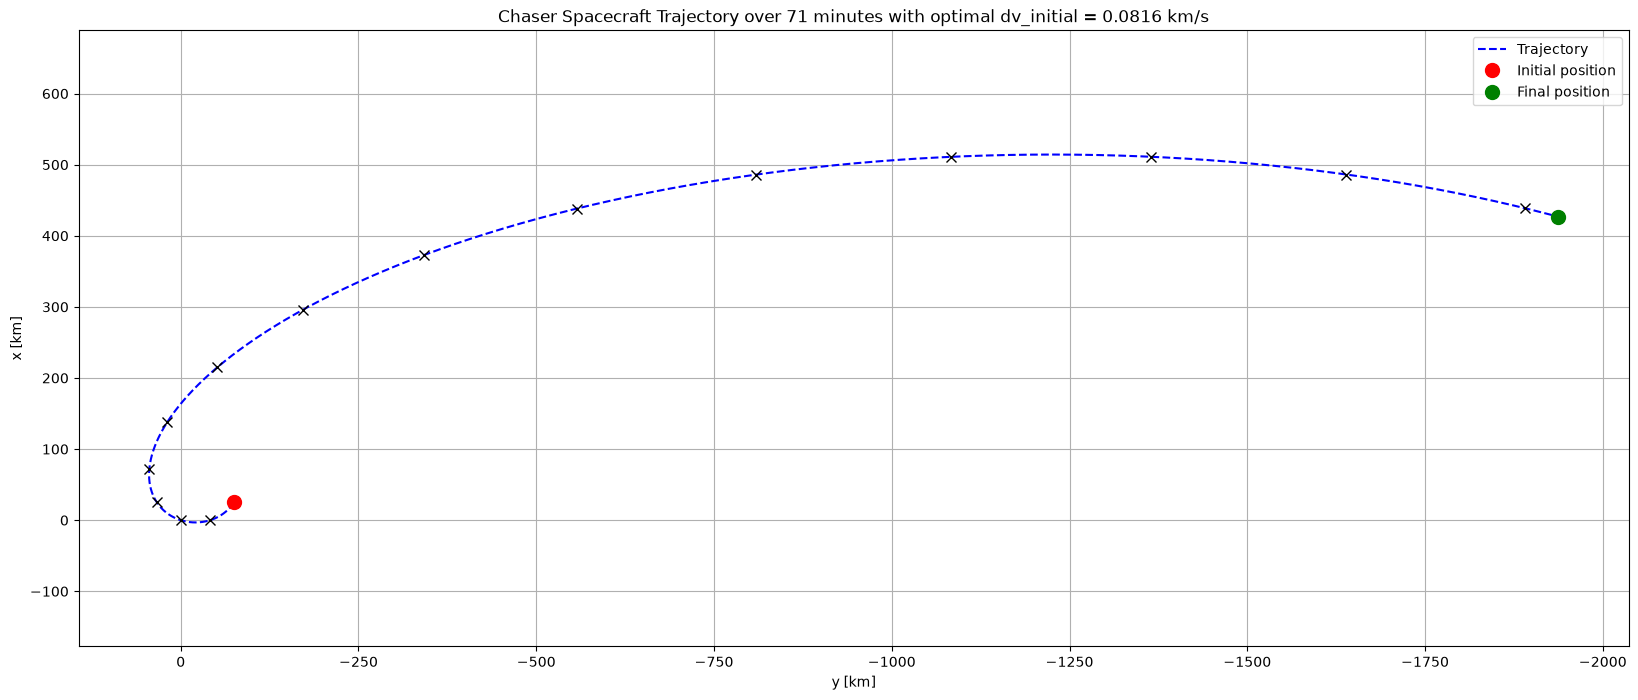

In [229]:
fig, ax = plt.subplots(figsize=(20, 8))
ax.set_title(f"Chaser Spacecraft Trajectory over {t_dv_min} minutes with optimal dv_initial = {dv_min:.4f} km/s")

# Trajectory
ax.plot(y_hcw, x_hcw, 'b--', label='Trajectory')

for i in range(0, len(x_hcw), 5*MIN_TO_SEC):
    ax.plot(y_hcw[i], x_hcw[i], 'kx', markersize=7)

ax.plot(y_hcw[0], x_hcw[0], 'ro', markersize=10, label='Initial position')
ax.plot(y_hcw[-1], x_hcw[-1], 'go', markersize=10, label='Final position')

ax.set_xlabel('y [km]')
ax.set_ylabel('x [km]')
ax.set_aspect('equal', adjustable='datalim')
ax.set_xinverted(True)

ax.grid(True)
ax.legend()
plt.show()

## Problem 4